# Creating and Backtesting SMA/EMA Crossovers

## Creating the SMAEMABacktester Class (based on EMABacktester)

In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brute
%config InlineBackened.format_figure = "retina"

In [95]:
import warnings
warnings.filterwarnings(action = "ignore")

In [110]:
class EMASMABackTester():
    '''Class for the vectorized backtesting of EMA/SMA based trading strategies:
    Attributes:
    ===========
    symbol: str
        The ticker that we want to trade.
    EMA: int
        Emponential Moving Average
    SMA: int
        Simple Moving Average
    start: str
        The start date for the backtesting period in YYYY-MM-DD format
    end: str
        The end date for the backtesting period in YYYY-MM-DD format
    tc: float
        The trading cost for the backtest (e.g. 0.001 = 0.1%)

    Methods:
    ========
    get_data():
    EMASMA_trading_strategy(displaying_mode = None):
    plot_results()
    set_EMASMA_parameters(new_EMA , new_SMA):
    update_trading_strategy((EMA , SMA) , displaying_mode = None)
    optimizing_trading_parameter((EMAs_range : (start , stop , step) , SMAs_range : (start , stop , step)))

    '''
    def __init__(self , symbol , EMA , SMA , start , end , tc):
        self.symbol = symbol
        self.EMA = EMA
        self.SMA = SMA
        self.start = start
        self.end = end
        self.tc = tc
        self.data = None
        self.results = None
        self.get_data()

    def __repr__(self) -> str:
        rep = f"EMASMABackTester(symbol={self.symbol}|EMA={self.EMA}|SMA={self.SMA}|start={self.start}|end={self.end}|tc={self.tc})"
        return rep

    def get_data(self):
        '''Load the raw price data and compute initial EMA & SMA'''
        try:
            raw = pd.read_csv("forex_pairs.csv" , parse_dates=["Date"], index_col=["Date"])
        except FileNotFoundError:
            raise FileNotFoundError("Please ensure 'forex_pairs.csv' is in the current directory.")
        
        raw = raw.loc[self.start:self.end , self.symbol].to_frame().dropna()
        raw.columns = ["price"]

        #Calculate EMA & SMA:
        raw["EMA"] = raw["price"].ewm(span = self.EMA , min_periods=self.EMA).mean()
        raw["SMA"] = raw["price"].rolling(window=self.SMA ,min_periods=self.SMA).mean()
        self.data = raw
        return raw

    def EMASMA_trading_strategy(self , displaying_mode = None):
        '''Implement the trading strategy & display its performance compared to Buy&Hold
        Parameters:
        ===========
        displaying_mode : str , optional
            'tabular': Returns styled KPI table.
            'value': Returns single numeric value (final cummulative strategy return).
            None: Prints message and stores results internally.        
        '''
        data = self.data.dropna().copy()
        if data.empty:
            raise ValueError("No valid data after dropping NaNs. Check start/end dates & EMA periods.")

        data["position"] = np.where(data["EMA"]>data["SMA"] , +1 , -1)
        data["trades"] = data["position"].diff().fillna(value = 0).abs()
        data["log_ret"] = np.log(data["price"]/data["price"].shift(1))
        
        # Strategy Returns: 
        # Position shifted by 1 because signal generated at close t affects return t+1
        # Subtract transaction costs (approximated linearly for simplicity)
        data["strategy"] = data["position"].shift(1)*data["log_ret"] - data["trades"] * self.tc

        # Cumulative Metrics:
        data["cum_log_ret"] = np.exp(data["log_ret"].cumsum())
        data["cum_strategy"] = np.exp(data["strategy"].cumsum())

        data = data.dropna()

        if data.empty:
            raise ValueError("Insufficient data points to calculate metric after processing.")

        # Extract Final Performance Values:
        strat_perf = data["cum_strategy"].iloc[-1]
        bh_perf = data["cum_log_ret"].iloc[-1]
        out_perf = strat_perf - bh_perf

        #Annualized Stats:
        ann_factor = 252 # 252 trading days in a fiscal year
        sqrt_ann_factor = np.sqrt(ann_factor)

        kpi_dict = {
            "Absolute Performance of Strategy" : strat_perf ,
            "Buy & Hold Perf": bh_perf , 
            "Ann. Return B&H": data["log_ret"].mean() * ann_factor,
            "Ann. Risk B&H" : data["log_ret"].std() * sqrt_ann_factor,
            "Ann. Return Strat": data["strategy"].mean() * ann_factor,
            "Ann. Risk Strat" : data["strategy"].std() * sqrt_ann_factor
        }

        index_label = f"Results: EMA:{self.EMA} | SMA:{self.SMA}"
        self.KPI = pd.DataFrame(data = kpi_dict , index = [index_label]).T

        # Style formatting for tabular view:
        self.KPI_table = self.KPI.style.format("{:.2%}")

        #Store detailed results for plotting:
        self.results = data

        if displaying_mode == "tabular":
            return self.KPI_table
        elif displaying_mode == "value":
            return float(strat_perf)

        else:
            print("Displaying mode is not specified. Results stored in .result and .KPI")
            return None

    def plot_results(self):
        '''Plot Strategy vs Buy&Hold equity curves.
        '''
        if self.results is None or self.results.empty:
            print("There is nothing to display! Run EMASMA_trading_strategy() first.")
        else:        
            self.results.dropna().iloc[:,-2:].plot(figsize = (16,8))
            plt.title(f"EMAEMA Strategy VS Buy& Hold\n {self.symbol}: {self.EMA} | {self.SMA}" , fontsize = 18)
            plt.ylabel("Value ($)" , fontsize = 13)
            plt.xlabel("Date" , fontsize = 13)
            plt.autoscale(enable = True , axis ="x" , tight = True)
            plt.gca().spines[["top","right"]].set_visible(False)
            plt.legend(labels = ["Buy & Hold" , "Strategy"] , fontsize = 12 , loc = (.8,1.01) , fancybox = True , frameon = True , facecolor = "cornsilk" , shadow = True)
            plt.grid(axis = "y")
            plt.show()

    def set_EMASMA_parameters(self , new_EMA , new_SMA):
        '''Update the new EMA & new SMA parameters and recalculate the EMA & SMA on the existing data.
        '''
        if self.data is None or self.data.empty:
            raise AttributeError("Data not loaded. Call get_data() first.")
        raw_new = self.data[["price"]].copy()
        if new_EMA is not None:
            self.EMA = int(new_EMA)
        if new_SMA is not None:
            self.SMA = int(new_SMA)      
                        
        raw_new["EMA"] = raw_new["price"].ewm(span = self.EMA , min_periods = self.EMA).mean()
        raw_new["SMA"] = raw_new["price"].rolling(window = self.SMA , min_periods = self.SMA).mean()
        self.data = raw_new
    
    def optimizing_trading_parameters(self , EMA_range:tuple , SMA_range:tuple)->float:
        '''
        Finding the best EMA & SMA with the highest strategy return using grid search (brute force).
        Parameters:
        ===========
        EMA_range: tuple
            (start , stop , step) for EMA
        SMA_range: tuple
            (start , stop , step) for SMA

        Returns:
        ========
        best_parameters: ndarray
            Array [EMA , SMA] for the best EMA & SMA
        best_results: DataFrame/Styler
            DataFrame/Styler with the best EMA & SMA and their corresponding strategy return
        '''
        def objective(x):
             '''Objective function to maximize the strategy return.'''
             self.set_EMASMA_parameters(x[0] , x[1])
             perf_value = self.EMASMA_trading_strategy(displaying_mode="value")
             return -1 * perf_value
        
        ranges = (EMA_range , SMA_range)
        print("Starting optimization... This may take some time depending on range size.")
        res = brute(objective , ranges=ranges)
        #full_output = True , disp = True , workers = 1
        best_EMA , best_SMA = res[0] , res[1]
        print(f"Optimal Parameters found: EMA = {best_EMA} , SMA = {best_SMA}")
        self.set_EMASMA_parameters(new_EMA = best_EMA , new_SMA = best_SMA)
        best_results = self.EMASMA_trading_strategy(displaying_mode="tabular")
        # (best_EMA , best_SMA) , 
        return best_results
            

In [111]:
emasma = EMASMABackTester(symbol="EURUSD=X", EMA = 50, SMA = 50, start = "2004-01-01", end = "2020-06-30", tc = 0.00005)

In [112]:
emasma.symbol , emasma.EMA , emasma.SMA , emasma.start , emasma.end , emasma.tc

('EURUSD=X', 50, 50, '2004-01-01', '2020-06-30', 5e-05)

In [113]:
emasma.__repr__

<bound method EMASMABackTester.__repr__ of EMASMABackTester(symbol=EURUSD=X|EMA=50|SMA=50|start=2004-01-01|end=2020-06-30|tc=5e-05)>

In [114]:
emasma.data

,price,EMA,SMA
Date,,,
2004-01-01,1.258194,NaN,NaN
2004-01-02,1.258194,NaN,NaN
2004-01-05,1.268698,NaN,NaN
2004-01-06,1.272103,NaN,NaN
2004-01-07,1.264095,NaN,NaN
...,...,...,...
2020-06-24,1.131235,1.109674,1.101794
2020-06-25,1.125087,1.110279,1.102486
2020-06-26,1.122208,1.110746,1.103213


In [115]:
emasma.get_data()

,price,EMA,SMA
Date,,,
2004-01-01,1.258194,NaN,NaN
2004-01-02,1.258194,NaN,NaN
2004-01-05,1.268698,NaN,NaN
2004-01-06,1.272103,NaN,NaN
2004-01-07,1.264095,NaN,NaN
...,...,...,...
2020-06-24,1.131235,1.109674,1.101794
2020-06-25,1.125087,1.110279,1.102486
2020-06-26,1.122208,1.110746,1.103213


In [116]:
emasma.plot_results()

There is nothing to display! Run EMASMA_trading_strategy() first.


In [117]:
emasma.EMASMA_trading_strategy(displaying_mode="tabular")

,Results: EMA:50 | SMA:50
Absolute Performance of Strategy,116.25%
Buy & Hold Perf,91.95%
Ann. Return B&H,-0.50%
Ann. Risk B&H,12.03%
Ann. Return Strat,0.90%
Ann. Risk Strat,12.04%


In [118]:
emasma.EMASMA_trading_strategy(displaying_mode="value")

1.162458966045731

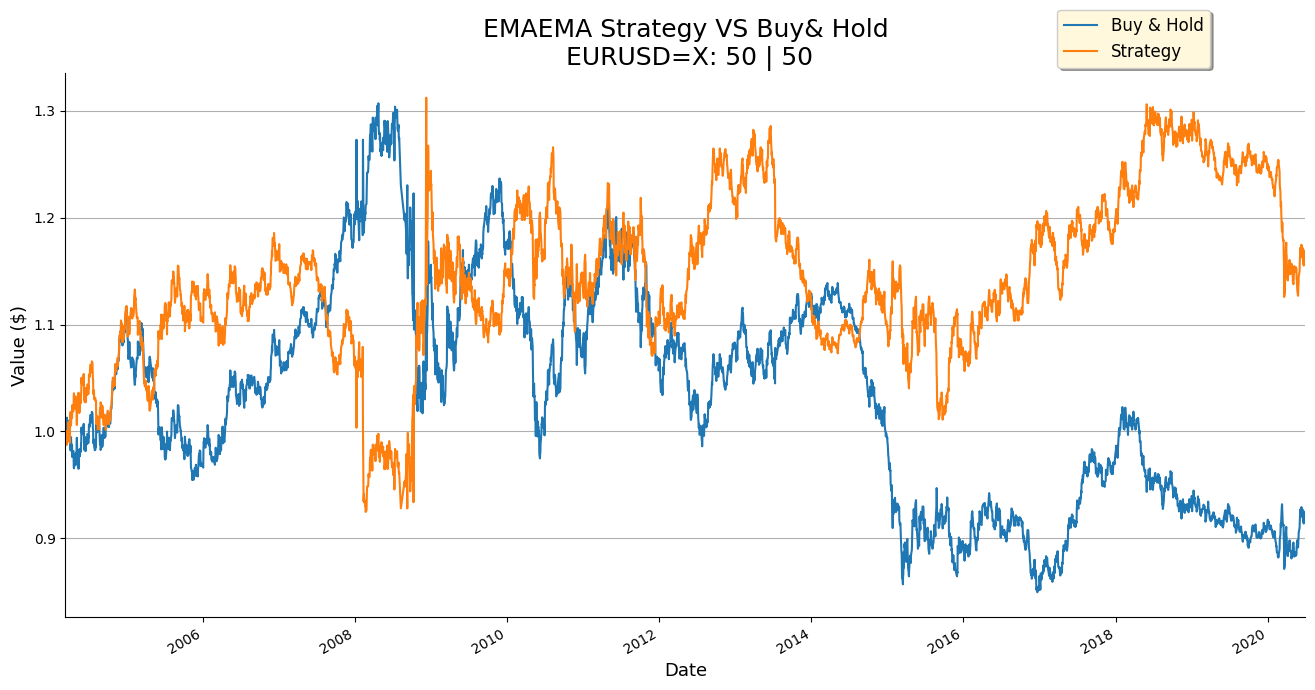

In [119]:
emasma.plot_results()

In [120]:
emasma.data

,price,EMA,SMA
Date,,,
2004-01-01,1.258194,NaN,NaN
2004-01-02,1.258194,NaN,NaN
2004-01-05,1.268698,NaN,NaN
2004-01-06,1.272103,NaN,NaN
2004-01-07,1.264095,NaN,NaN
...,...,...,...
2020-06-24,1.131235,1.109674,1.101794
2020-06-25,1.125087,1.110279,1.102486
2020-06-26,1.122208,1.110746,1.103213


In [121]:
emasma.results

,price,EMA,SMA,position,trades,log_ret,strategy,cum_log_ret,cum_strategy
Date,,,,,,,,,
2004-03-11,1.235102,1.251285,1.256829,-1,0.0,0.009686,-0.009686,1.009733,0.990361
2004-03-12,1.222404,1.249991,1.256113,-1,0.0,-0.010334,0.010334,0.999352,1.000648
2004-03-15,1.227205,1.248975,1.255283,-1,0.0,0.003919,-0.003919,1.003277,0.996734
2004-03-16,1.226106,1.247962,1.254363,-1,0.0,-0.000896,0.000896,1.002379,0.997627
2004-03-17,1.222703,1.246848,1.253535,-1,0.0,-0.002779,0.002779,0.999596,1.000404
...,...,...,...,...,...,...,...,...,...
2020-06-24,1.131235,1.109674,1.101794,1,0.0,0.002892,0.002892,0.924818,1.169192
2020-06-25,1.125087,1.110279,1.102486,1,0.0,-0.005449,-0.005449,0.919793,1.162838
2020-06-26,1.122208,1.110746,1.103213,1,0.0,-0.002562,-0.002562,0.917439,1.159863


In [122]:
emasma.optimizing_trading_parameters(EMA_range=(10,200,1) , SMA_range=(10,200,1))

Starting optimization... This may take some time depending on range size.
Optimal Parameters found: EMA = 193.0 , SMA = 180.0


,Results: EMA:193 | SMA:180
Absolute Performance of Strategy,307.64%
Buy & Hold Perf,91.38%
Ann. Return B&H,-0.56%
Ann. Risk B&H,12.07%
Ann. Return Strat,6.94%
Ann. Risk Strat,12.07%


In [124]:
emasma.EMASMA_trading_strategy(displaying_mode="tabular")

,Results: EMA:193 | SMA:180
Absolute Performance of Strategy,307.64%
Buy & Hold Perf,91.38%
Ann. Return B&H,-0.56%
Ann. Risk B&H,12.07%
Ann. Return Strat,6.94%
Ann. Risk Strat,12.07%


In [125]:
emasma

EMASMABackTester(symbol=EURUSD=X|EMA=193|SMA=180|start=2004-01-01|end=2020-06-30|tc=5e-05)

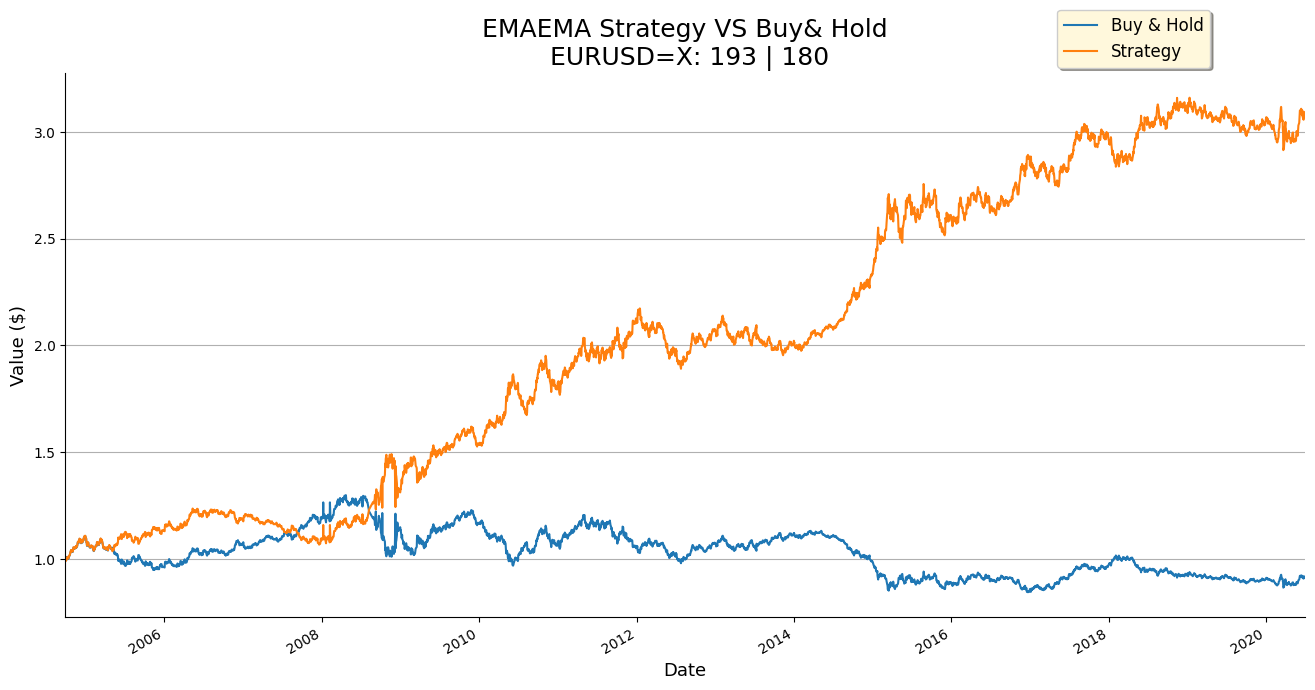

In [126]:
emasma.plot_results()

In [127]:
emasma.results

,price,EMA,SMA,position,trades,log_ret,strategy,cum_log_ret,cum_strategy
Date,,,,,,,,,
2004-09-28,1.232104,1.221243,1.223003,-1,0.0,0.001059,-0.001059,1.001060,0.998942
2004-09-29,1.233700,1.221391,1.222824,-1,0.0,0.001295,-0.001295,1.002356,0.997649
2004-09-30,1.243394,1.221653,1.222662,-1,0.0,0.007828,-0.007828,1.010233,0.989871
2004-10-01,1.241496,1.221888,1.222569,-1,0.0,-0.001528,0.001528,1.008690,0.991384
2004-10-04,1.228999,1.221972,1.222459,-1,0.0,-0.010116,0.010116,0.998537,1.001465
...,...,...,...,...,...,...,...,...,...
2020-06-24,1.131235,1.106196,1.103971,1,0.0,0.002892,0.002892,0.919105,3.094208
2020-06-25,1.125087,1.106390,1.104068,1,0.0,-0.005449,-0.005449,0.914111,3.077394
2020-06-26,1.122208,1.106553,1.104121,1,0.0,-0.002562,-0.002562,0.911772,3.069520


In [128]:
emasma.results.columns

Index(['price', 'EMA', 'SMA', 'position', 'trades', 'log_ret', 'strategy',
       'cum_log_ret', 'cum_strategy'],
      dtype='object')

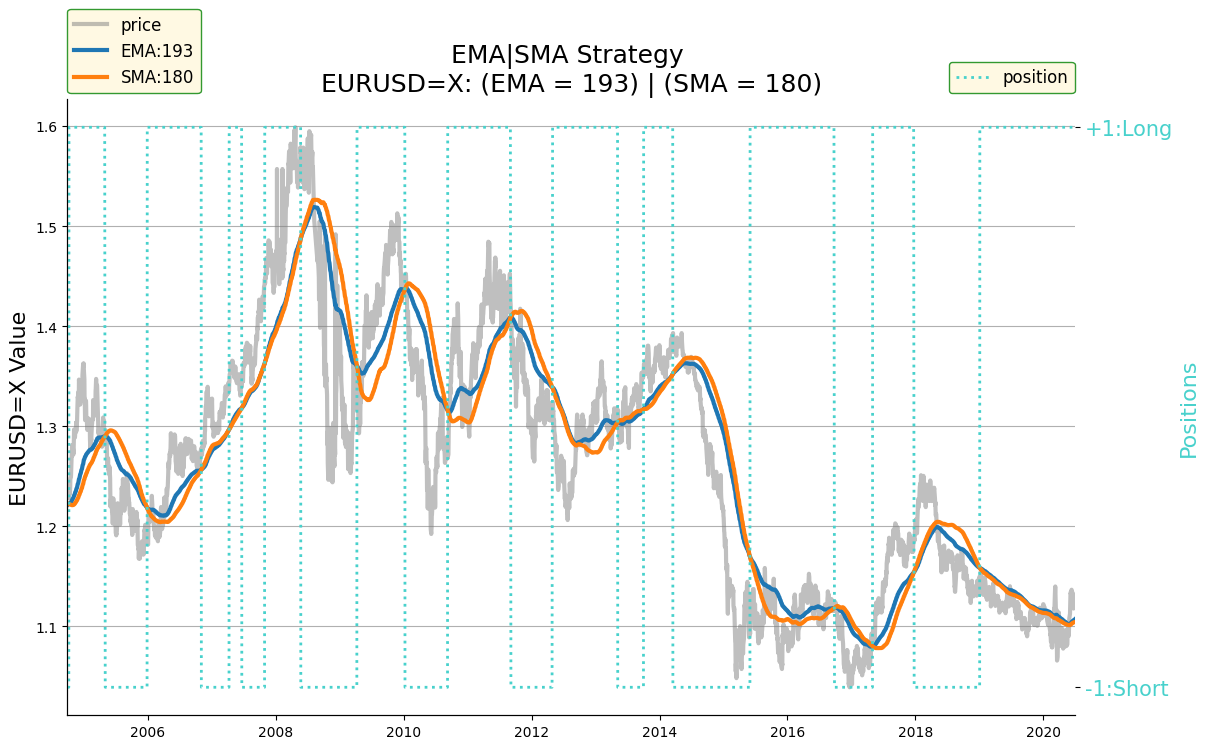

In [129]:
fig , ax = plt.subplots(1,1,figsize=(13,8))
emasma.results.loc[: , ["EMA","SMA","position"]]
ax.plot(emasma.results.loc[: , ["price"]] , label = "price" , color = "gray" , lw = 3 , alpha = 0.5)
ax.plot(emasma.results.loc[: , ["EMA"]] , label = "EMA:{}".format(emasma.EMA) , lw = 3)
ax.plot(emasma.results.loc[: , ["SMA"]] , label = "SMA:{}".format(emasma.SMA) , lw = 3)

ax.set_ylabel(f"{emasma.symbol} Value" , fontsize = 16)
ax.legend(fontsize = 12 ,
          loc = (0. , 1.01),
          frameon = True,
          fancybox = True,
          edgecolor = "green",
          facecolor = "cornsilk")
ax.spines[["top" , "right"]].set_visible(False)
ax.autoscale(enable=True , axis = "x" , tight=True)
ax.set_title(f"EMA|SMA Strategy \n{emasma.symbol}: (EMA = {emasma.EMA}) | (SMA = {emasma.SMA})" , fontsize = 18)
ax.grid(axis = "y")

ax2 = ax.twinx()
ax2.plot(emasma.results.loc[: , ["position"]], label = "position" , ls = ":" , color = "mediumturquoise" , lw = 2)
ax2.legend(fontsize = 12 ,
          loc = (0.875 , 1.01),
          frameon = True,
          fancybox = True,
          edgecolor = "green",
          facecolor = "cornsilk")
ax2.set_yticks([-1 , +1] , labels= ["-1:Short" , "+1:Long"] , fontsize = 15 , color = "mediumturquoise")
ax2.set_ylabel("Positions" , fontsize = 16 , color = "mediumturquoise")
ax2.spines[["top" , "right"]].set_visible(False)
ax2.autoscale(enable=True , axis = "x" , tight=True)

__AUD / EUR__

In [ ]:
tester = SMAEMA("AUDEUR=X", 50, 50, "2004-01-01", "2020-06-30", 0)

In [ ]:
tester.test_strategy()

In [ ]:
tester.plot_results()

In [ ]:
tester.optimize_parameters((20, 100, 1), (20, 100, 1))

In [ ]:
tester.plot_results()